In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = sns.load_dataset("taxis")

df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [4]:
print("Shape:", df.shape)

df.info()

Shape: (6433, 14)
<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5),

In [5]:
df.isnull().sum()


pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [7]:
numerical_cols = df.select_dtypes(include=np.number).columns

for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

df[numerical_cols].isnull().sum()

passengers    0
distance      0
fare          0
tip           0
tolls         0
total         0
dtype: int64

In [9]:
categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

df[categorical_cols].isnull().sum()

C:\Users\VISWANADH\AppData\Local\Temp\ipykernel_25740\653360391.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include='object').columns
C:\Users\VISWANADH\AppData\Local\Temp\ipykernel_25740\653360391.py:4: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For exampl

color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

In [10]:
df['pickup'] = pd.to_datetime(df['pickup'])

df['pickup'].head()

0   2019-03-23 20:21:09
1   2019-03-04 16:11:55
2   2019-03-27 17:53:01
3   2019-03-10 01:23:59
4   2019-03-30 13:27:42
Name: pickup, dtype: datetime64[us]

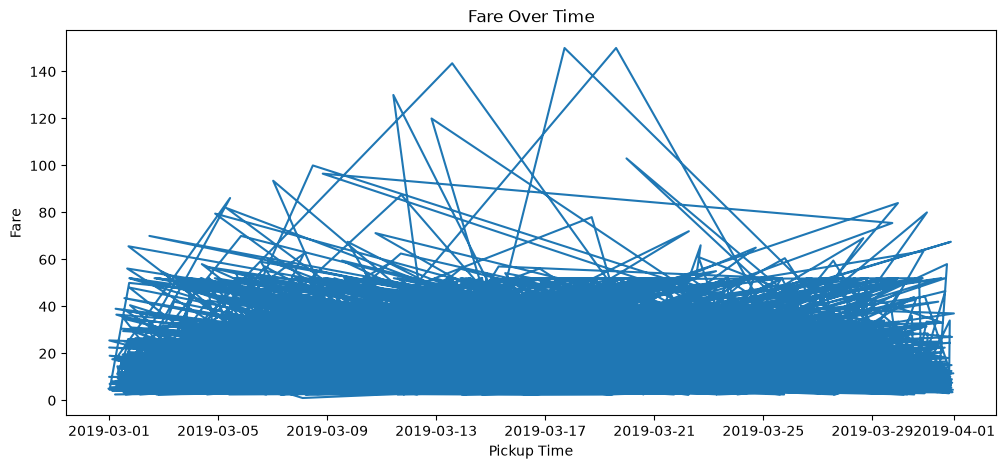

In [11]:
plt.figure(figsize=(12,5))

plt.plot(df['pickup'], df['fare'])

plt.title('Fare Over Time')
plt.xlabel('Pickup Time')
plt.ylabel('Fare')

plt.show()

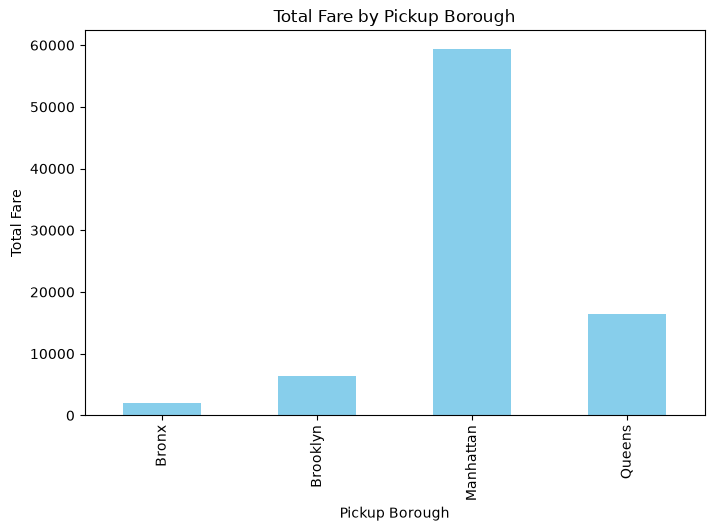

In [12]:
borough_fare = df.groupby('pickup_borough')['fare'].sum()

borough_fare.plot(
    kind='bar',
    figsize=(8,5),
    color='skyblue'
)

plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')

plt.show()

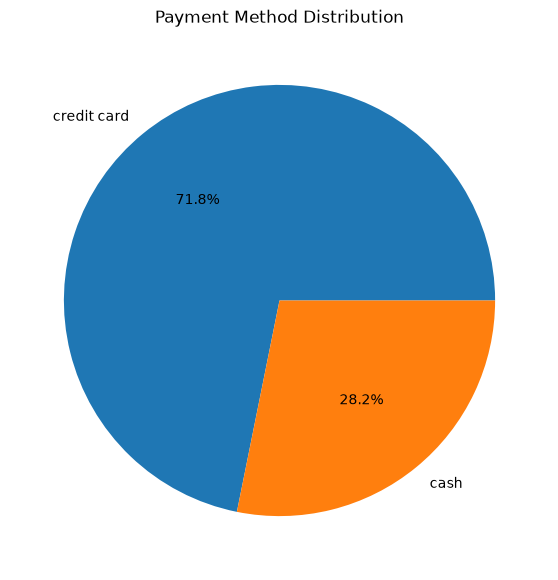

In [13]:
payment_counts = df['payment'].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%'
)

plt.title('Payment Method Distribution')

plt.show()


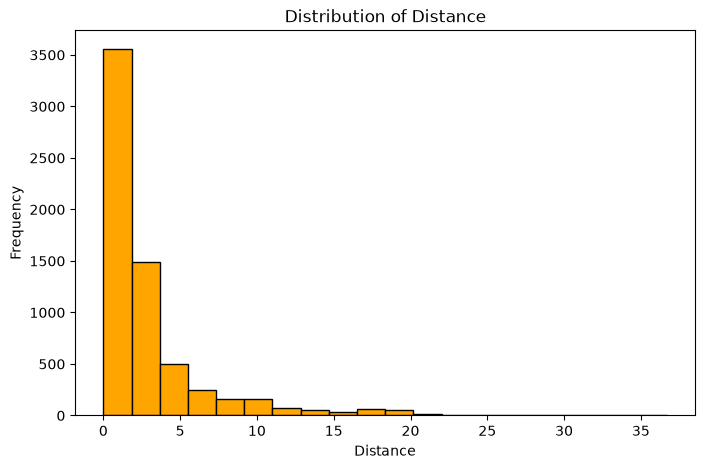

In [14]:
plt.figure(figsize=(8,5))

plt.hist(
    df['distance'],
    bins=20,
    color='orange',
    edgecolor='black'
)

plt.title('Distribution of Distance')
plt.xlabel('Distance')
plt.ylabel('Frequency')

plt.show()

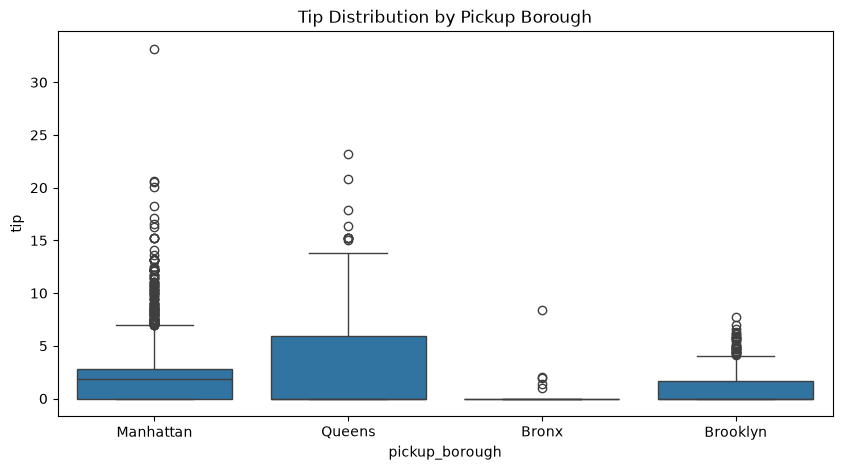

In [15]:
plt.figure(figsize=(10,5))

sns.boxplot(
    x='pickup_borough',
    y='tip',
    data=df
)

plt.title('Tip Distribution by Pickup Borough')

plt.show()

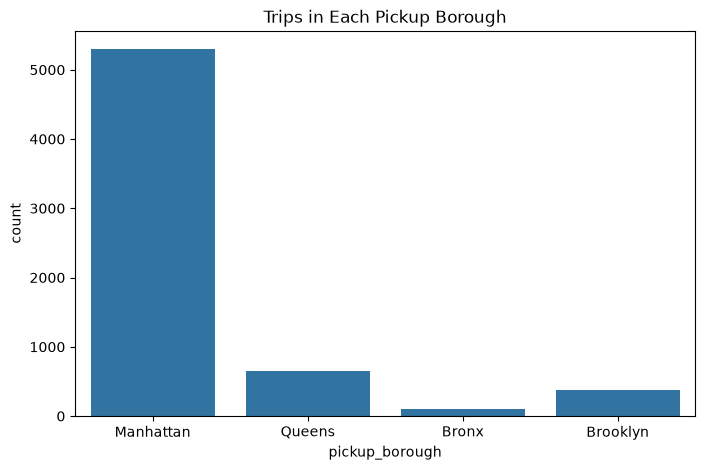

In [16]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='pickup_borough',
    data=df
)

plt.title('Trips in Each Pickup Borough')

plt.show()

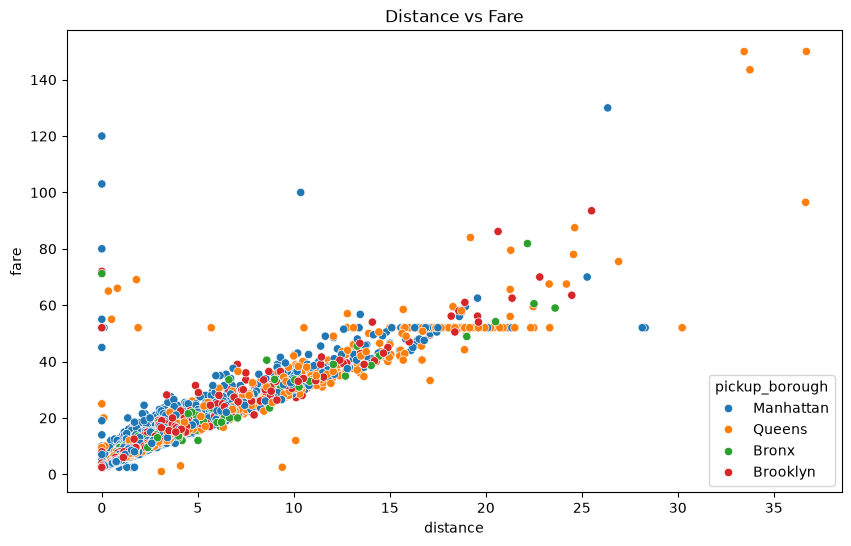

In [17]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x='distance',
    y='fare',
    hue='pickup_borough',
    data=df
)

plt.title('Distance vs Fare')

plt.show()

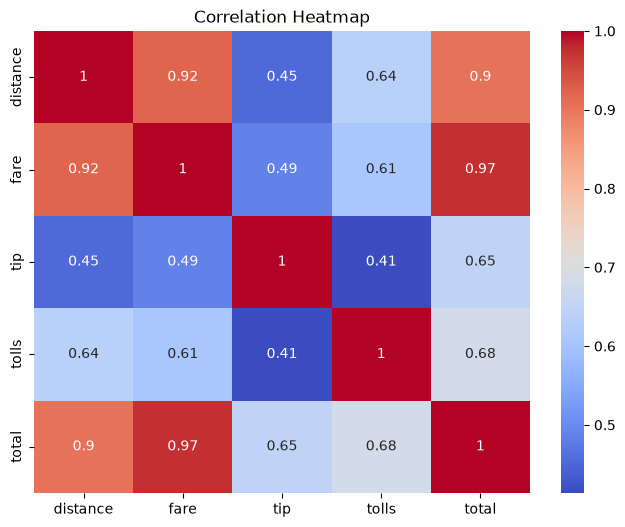

In [20]:
corr = df[
    ['distance','fare','tip','tolls','total']
].corr()

plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')

plt.show()

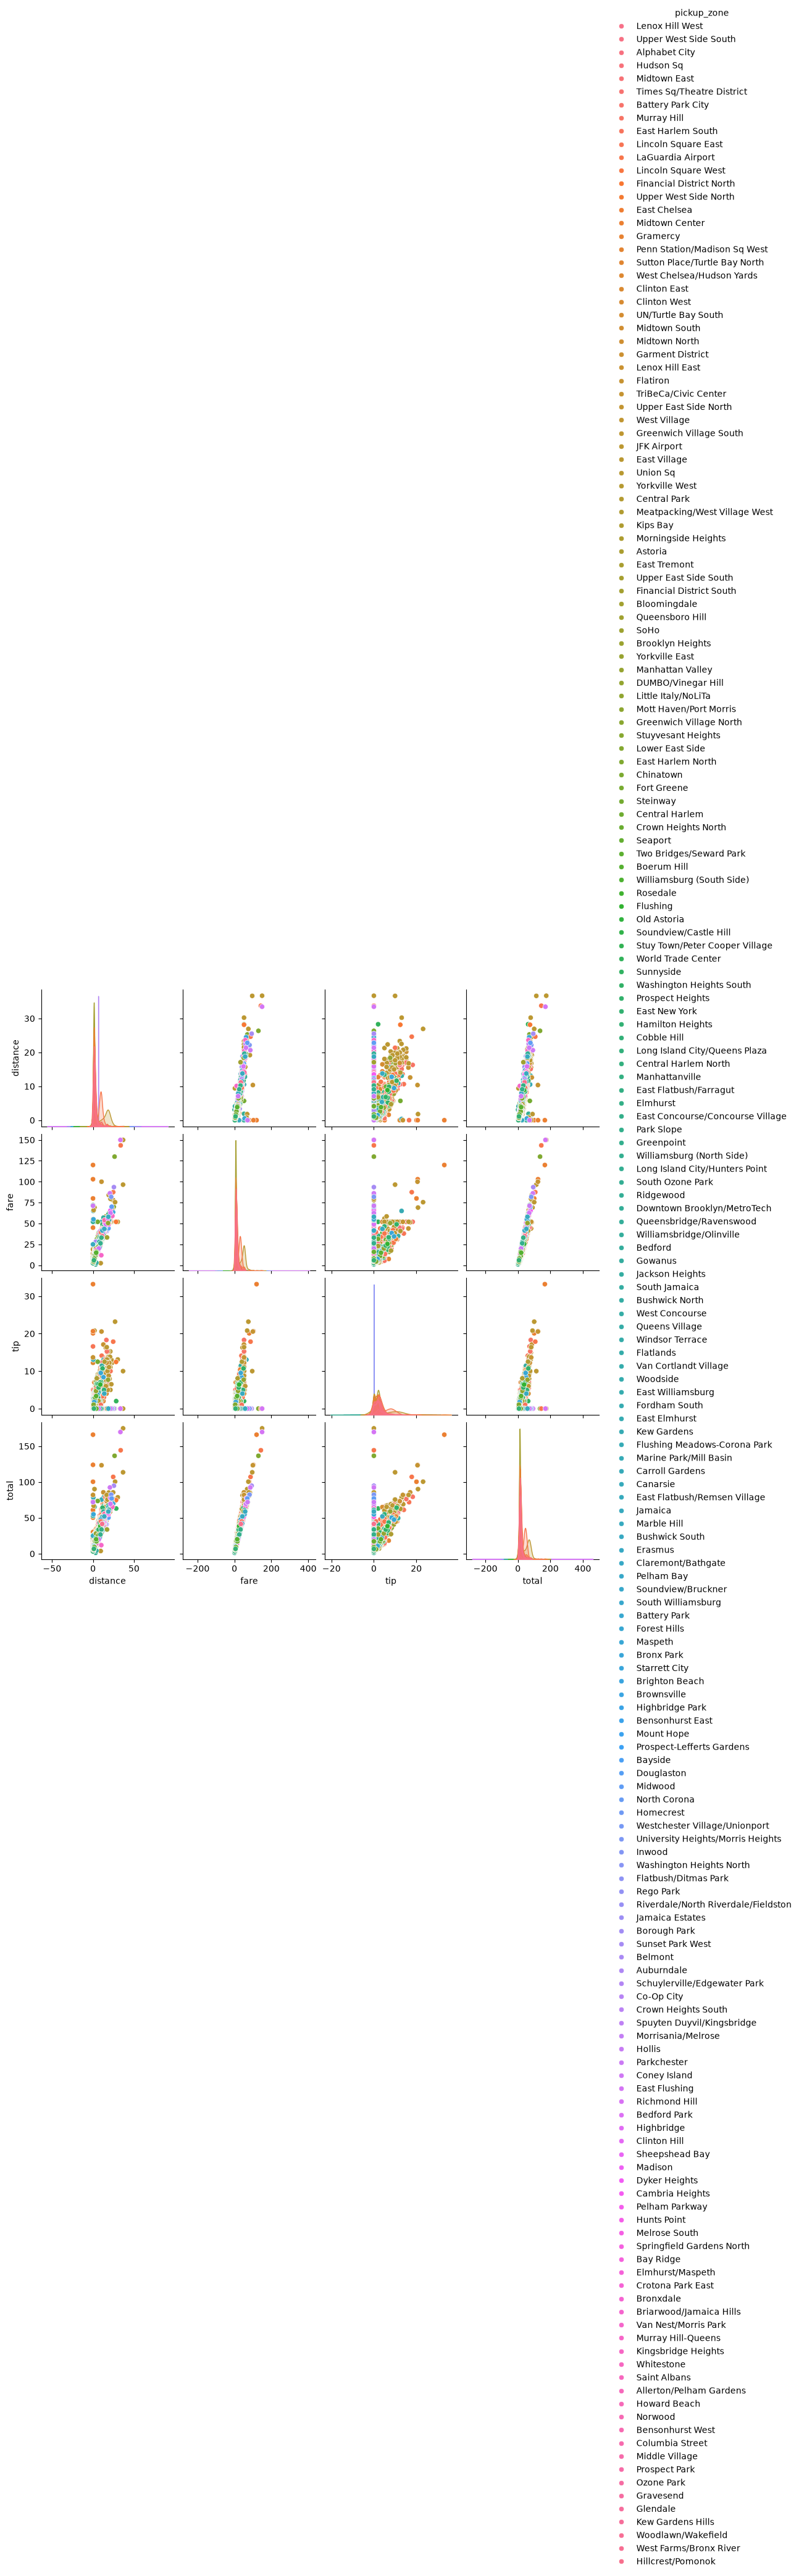

In [21]:
sns.pairplot(
    df[
        ['distance',
         'fare',
         'tip',
         'total',
         'pickup_zone']
    ],
    hue='pickup_zone'
)

plt.show()

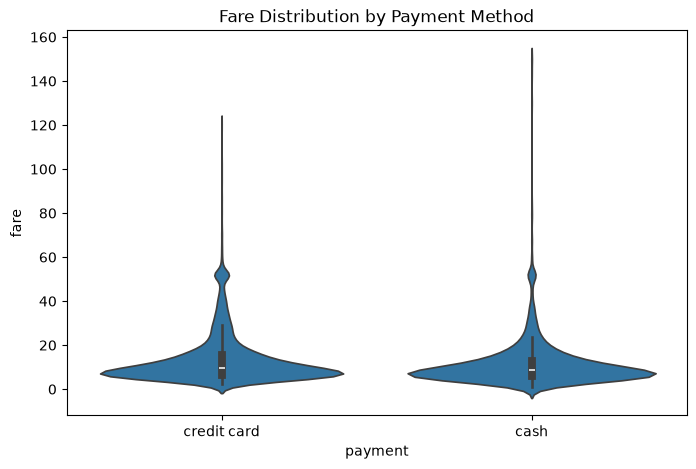

In [22]:
plt.figure(figsize=(8,5))

sns.violinplot(
    x='payment',
    y='fare',
    data=df
)

plt.title('Fare Distribution by Payment Method')

plt.show()

In [23]:
df.isnull().sum()


pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64